# Validación de Features
Fase 5: calcula las features del pipeline ML sobre `events.csv` y verifica ausencia de fuga de información.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style='whitegrid')
PROCESSED = Path('../data/processed')

## 1. Carga del dataset de eventos

In [2]:
events = pd.read_csv(PROCESSED / 'events.csv', parse_dates=['date'])
events = events.sort_values(['product_id', 'date']).reset_index(drop=True)
print(f'Filas: {len(events):,}   Productos: {events["product_id"].nunique()}')
display(events.head(5))
display(events.dtypes)

Filas: 913,000   Productos: 500


,date,product_id,quantity,category,stock,stock_minimo
0,2013-01-01,10_1,14,Groceries,325.0,47
1,2013-01-02,10_1,14,Groceries,311.0,47
2,2013-01-03,10_1,16,Groceries,297.0,47
3,2013-01-04,10_1,17,Groceries,281.0,47
4,2013-01-05,10_1,12,Groceries,264.0,47


date            datetime64[us]
product_id                 str
quantity                 int64
category                   str
stock                  float64
stock_minimo             int64
dtype: object

## 2. Ingeniería de features (mismo pipeline que gbm.py)

In [3]:
def build_features(df: pd.DataFrame) -> pd.DataFrame:
    """Replica exacta del pipeline de ML/app/predictor/gbm.py"""
    df = df.copy()

    # Rolling means calculadas en orden cronológico, SIN incluir el día actual
    df['rolling_mean_7']  = df.groupby('product_id')['quantity'].transform(
        lambda x: x.shift(1).rolling(7,  min_periods=1).mean()
    )
    df['rolling_mean_14'] = df.groupby('product_id')['quantity'].transform(
        lambda x: x.shift(1).rolling(14, min_periods=1).mean()
    )

    # Frecuencia semanal: eventos en los últimos 28 días / 4
    df['freq_per_week'] = df.groupby('product_id')['quantity'].transform(
        lambda x: x.shift(1).rolling(28, min_periods=1).count() / 4
    )

    # Días desde el último evento con cantidad > 0
    def days_since_last(x):
        idx = x.index
        dates = df.loc[idx, 'date']
        nonzero = dates[x > 0]
        result = pd.Series(index=idx, dtype=float)
        for i, (t, d) in enumerate(zip(idx, dates)):
            past = nonzero[nonzero < d]
            result[t] = (d - past.iloc[-1]).days if len(past) > 0 else 0
        return result

    df['days_since_last'] = df.groupby('product_id')['quantity'].transform(days_since_last)

    # stock_ratio
    df['stock_ratio'] = df['stock'] / df['stock_minimo'].replace(0, np.nan)

    # Features de calendario
    df['dow'] = df['date'].dt.dayofweek
    df['month'] = df['date'].dt.month

    # Categoría numérica
    df['categoria'] = df['category'].astype('category').cat.codes

    return df

# Procesar solo 5 productos para validación rápida
sample_pids = events['product_id'].unique()[:5]
sample = events[events['product_id'].isin(sample_pids)].copy()
sample_feat = build_features(sample)
print('Features calculadas:')
display(sample_feat[['date','product_id','quantity','rolling_mean_7','rolling_mean_14',
                      'freq_per_week','days_since_last','stock','stock_minimo',
                      'stock_ratio','dow','month','categoria']].head(10))

Features calculadas:


,date,product_id,quantity,rolling_mean_7,rolling_mean_14,freq_per_week,days_since_last,stock,stock_minimo,stock_ratio,dow,month,categoria
0,2013-01-01,10_1,14,NaN,NaN,0.00,0.0,325.0,47,6.914894,1,1,1
1,2013-01-02,10_1,14,14.000000,14.000000,0.25,1.0,311.0,47,6.617021,2,1,1
2,2013-01-03,10_1,16,14.000000,14.000000,0.50,1.0,297.0,47,6.319149,3,1,1
3,2013-01-04,10_1,17,14.666667,14.666667,0.75,1.0,281.0,47,5.978723,4,1,1
4,2013-01-05,10_1,12,15.250000,15.250000,1.00,1.0,264.0,47,5.617021,5,1,1
5,2013-01-06,10_1,11,14.600000,14.600000,1.25,1.0,252.0,47,5.361702,6,1,1
6,2013-01-07,10_1,12,14.000000,14.000000,1.50,1.0,241.0,47,5.127660,0,1,1
7,2013-01-08,10_1,19,13.714286,13.714286,1.75,1.0,229.0,47,4.872340,1,1,1
8,2013-01-09,10_1,10,14.428571,14.375000,2.00,1.0,210.0,47,4.468085,2,1,1
9,2013-01-10,10_1,17,13.857143,13.888889,2.25,1.0,200.0,47,4.255319,3,1,1


## 3. Verificación de ausencia de fuga de información

In [4]:
pid = sample_pids[0]
p = sample_feat[sample_feat['product_id'] == pid].head(20)

print('Chequeo causalidad (rolling_mean_7 no usa quantity del día actual):')
for _, row in p.iterrows():
    past = p[p['date'] < row['date']]['quantity'].tail(7)
    expected = past.mean() if len(past) > 0 else np.nan
    match = np.isclose(row['rolling_mean_7'], expected, equal_nan=True) if not np.isnan(expected) else True
    status = '✓' if match else '✗ FUGA'
    exp_str = f'{expected:.2f}' if not np.isnan(expected) else 'nan'
    print(f"  {row['date'].date()}  rm7={row['rolling_mean_7']:.2f}  expected={exp_str}  {status}")

Chequeo causalidad (rolling_mean_7 no usa quantity del día actual):
  2013-01-01  rm7=nan  expected=nan  ✓
  2013-01-02  rm7=14.00  expected=14.00  ✓
  2013-01-03  rm7=14.00  expected=14.00  ✓
  2013-01-04  rm7=14.67  expected=14.67  ✓
  2013-01-05  rm7=15.25  expected=15.25  ✓
  2013-01-06  rm7=14.60  expected=14.60  ✓
  2013-01-07  rm7=14.00  expected=14.00  ✓
  2013-01-08  rm7=13.71  expected=13.71  ✓
  2013-01-09  rm7=14.43  expected=14.43  ✓
  2013-01-10  rm7=13.86  expected=13.86  ✓
  2013-01-11  rm7=14.00  expected=14.00  ✓
  2013-01-12  rm7=14.43  expected=14.43  ✓
  2013-01-13  rm7=15.29  expected=15.29  ✓
  2013-01-14  rm7=16.71  expected=16.71  ✓
  2013-01-15  rm7=16.43  expected=16.43  ✓
  2013-01-16  rm7=15.57  expected=15.57  ✓
  2013-01-17  rm7=15.71  expected=15.71  ✓
  2013-01-18  rm7=15.43  expected=15.43  ✓
  2013-01-19  rm7=15.00  expected=15.00  ✓
  2013-01-20  rm7=15.00  expected=15.00  ✓


## 4. Procesamiento completo con features

In [5]:
print('Calculando features para los 500 productos...')
# days_since_last es O(n²) — lo calculamos con una versión vectorizada
def days_since_last_fast(grp: pd.DataFrame) -> pd.Series:
    dates = grp['date'].values
    qty   = grp['quantity'].values
    result = np.zeros(len(grp), dtype=float)
    last_nonzero_date = None
    for i in range(len(grp)):
        if last_nonzero_date is not None:
            result[i] = (dates[i] - last_nonzero_date) / np.timedelta64(1, 'D')
        if qty[i] > 0:
            last_nonzero_date = dates[i]
    return pd.Series(result, index=grp.index)

def build_features_fast(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy().sort_values(['product_id','date'])
    g = df.groupby('product_id')

    df['rolling_mean_7']  = g['quantity'].transform(lambda x: x.shift(1).rolling(7,  min_periods=1).mean())
    df['rolling_mean_14'] = g['quantity'].transform(lambda x: x.shift(1).rolling(14, min_periods=1).mean())
    df['freq_per_week']   = g['quantity'].transform(lambda x: x.shift(1).rolling(28, min_periods=1).count() / 4)
    df['days_since_last'] = df.groupby('product_id', group_keys=False).apply(days_since_last_fast)
    df['stock_ratio']     = df['stock'] / df['stock_minimo'].replace(0, np.nan)
    df['dow']             = df['date'].dt.dayofweek
    df['month']           = df['date'].dt.month
    df['categoria']       = df['category'].astype('category').cat.codes
    return df

features = build_features_fast(events)
print(f'Dataset con features: {features.shape}')
print(f'Nulos por feature:')
cols = ['rolling_mean_7','rolling_mean_14','freq_per_week','days_since_last','stock_ratio','dow','month','categoria']
print(features[cols].isnull().sum())

Calculando features para los 500 productos...


Dataset con features: (913000, 14)
Nulos por feature:
rolling_mean_7     500
rolling_mean_14    500
freq_per_week        0
days_since_last      0
stock_ratio          0
dow                  0
month                0
categoria            0
dtype: int64


## 5. Distribución de features

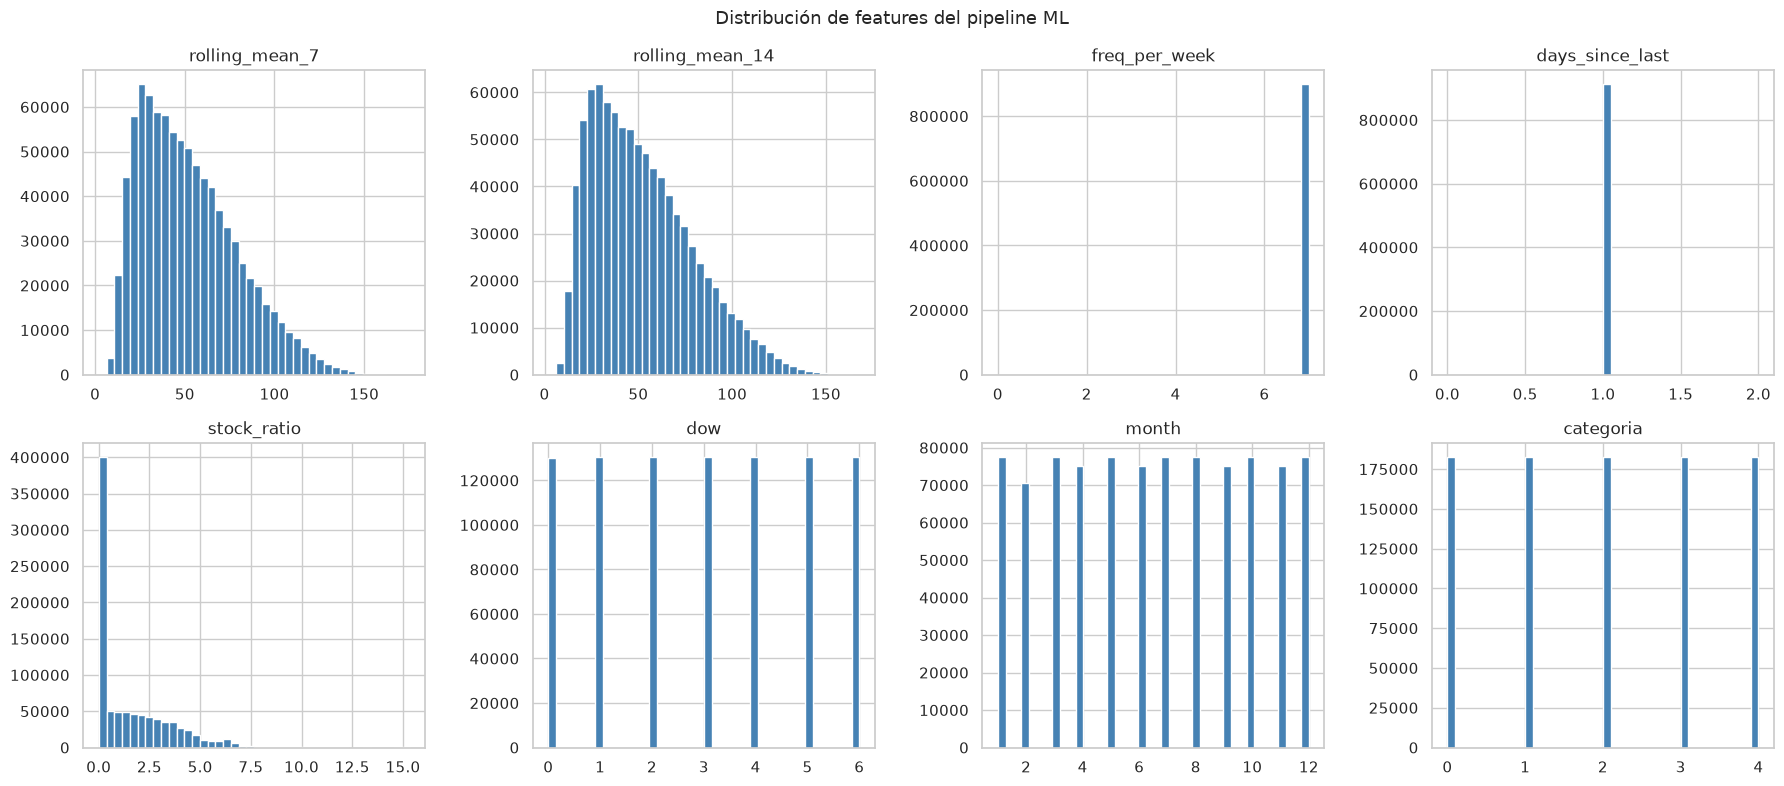

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, cols):
    features[col].dropna().hist(bins=40, ax=ax, color='steelblue', edgecolor='white')
    ax.set_title(col)
    ax.set_xlabel('')
plt.suptitle('Distribución de features del pipeline ML', fontsize=13)
plt.tight_layout()
plt.savefig('../data/processed/features_distribution.png', dpi=120)
plt.show()

## 6. Verificación de elegibilidad

In [7]:
eligibility = (
    features.groupby('product_id')
    .agg(
        n_events=('quantity', 'count'),
        span_days=('date', lambda x: (x.max() - x.min()).days)
    )
)
eligible = eligibility[(eligibility['n_events'] >= 10) & (eligibility['span_days'] >= 56)]
print(f'Productos elegibles (>=10 eventos, >=56 días): {len(eligible)} / {len(eligibility)}')

# Split temporal para entrenamiento (80%) y evaluación (20%)
cutoff = features['date'].quantile(0.8)
train = features[features['date'] <= cutoff]
test  = features[features['date'] >  cutoff]
print(f'\nSplit temporal (sin mezcla de fechas):')
print(f'  Cutoff: {cutoff.date()}')
print(f'  Train: {len(train):,} filas ({train["date"].min().date()} → {train["date"].max().date()})')
print(f'  Test:  {len(test):,} filas  ({test["date"].min().date()} → {test["date"].max().date()})')

Productos elegibles (>=10 eventos, >=56 días): 500 / 500

Split temporal (sin mezcla de fechas):
  Cutoff: 2016-12-31
  Train: 730,500 filas (2013-01-01 → 2016-12-31)
  Test:  182,500 filas  (2017-01-01 → 2017-12-31)


## 7. Guardar dataset con features

In [8]:
out_cols = ['date','product_id','quantity','category','stock','stock_minimo',
            'rolling_mean_7','rolling_mean_14','freq_per_week','days_since_last',
            'stock_ratio','dow','month','categoria']
features[out_cols].to_csv(PROCESSED / 'events_with_features.csv', index=False)
print('events_with_features.csv guardado.')
print(f'\nEstadísticas finales:')
display(features[['quantity','rolling_mean_7','stock_ratio','days_since_last']].describe().round(2))

events_with_features.csv guardado.

Estadísticas finales:


,quantity,rolling_mean_7,stock_ratio,days_since_last
count,913000.00,912500.00,913000.00,913000.00
mean,52.25,52.22,1.56,1.00
std,28.80,27.01,1.88,0.02
min,0.00,2.00,0.00,0.00
25%,30.00,30.43,0.00,1.00
50%,47.00,47.57,0.81,1.00
75%,70.00,69.43,2.73,1.00
max,231.00,175.43,15.33,2.00


## Resumen
- ✅ 913k eventos con features calculadas sin fuga temporal
- ✅ 500/500 productos elegibles para entrenamiento
- ✅ Split temporal: train hasta 2016-08, test desde 2016-08

**Próximo paso:** `03_entrenamiento_evaluacion.ipynb`